# 05 — Phase 5 · Experiment 3 — Feature reduction (H3, Q3, Q4)

## Question
How many variables are actually needed, and what does that buy in inference
cost?

## Hypothesis H3
A fraction of the 77 features retains most of the performance; a smaller set
also reduces inference latency.

## Protocol
- Same leak-free split, seeds 42/43/44, training capped at 20,000 rows per
  class for runtime.
- Selection fitted **inside the training fold only** with
  `mutual_info_classif`; random-forest impurity importance is the cross-check.
- Variants: all 77 features, ~75 % (58), ~50 % (39), ~25 % (20), Top-10.
  The constant columns are removed by the pipeline, so the effective count is
  reported alongside the requested count.
- For each variant: Macro-F1 and inference latency.  Latency = median of five
  `predict` calls on a 1,000-row batch, including preprocessing.
- Results come from `uv run daf-projet exp3`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

ROOT = Path.cwd()
if not (ROOT / "dataset").exists():
    ROOT = ROOT.parent
RES = ROOT / "results"
FIG = ROOT / "figures"

results = pd.read_csv(RES / "exp3.csv")
ranking = pd.read_csv(RES / "exp3_feature_ranking.csv")
display(results.head())
display(results.groupby(["task", "variant"]).size())

,n_test,n_classes,macro_f1,weighted_f1,accuracy,pr_auc,roc_auc,fpr,fpr_at_tpr95,task,...,model,seed,sklearn_version,n_train,n_features_in,n_features_effective,fit_seconds,predict_seconds,latency_ms_1000,throughput_flows_s
0,83777,2,0.998722,0.999105,0.999105,0.999995,0.999986,0.001003,0.000000,binary,...,random_forest,42,1.9.1,125007,77,65,6.103116,0.168589,46.144029,21671.276255
1,83777,2,0.998722,0.999105,0.999105,0.999998,0.999992,0.001109,0.000000,binary,...,random_forest,42,1.9.1,125007,77,58,29.320143,0.184051,46.558897,21478.172045
2,83777,2,0.997836,0.998485,0.998484,0.999995,0.999983,0.001953,0.000000,binary,...,random_forest,42,1.9.1,125007,77,39,30.368525,0.171658,46.792731,21370.840697
3,83777,2,0.996115,0.997280,0.997278,0.999935,0.999820,0.004699,0.000053,binary,...,random_forest,42,1.9.1,125007,77,20,31.065496,0.143312,46.642289,21439.771105
4,83777,2,0.993254,0.995276,0.995273,0.999543,0.999064,0.008817,0.000968,binary,...,random_forest,42,1.9.1,125007,77,10,28.238633,0.150385,58.362420,17134.313485


task        variant
binary      25pct      3
            50pct      3
            75pct      3
            all        3
            top10      3
multiclass  25pct      3
            50pct      3
            75pct      3
            all        3
            top10      3
dtype: int64

,task,variant,n_features_effective,macro_f1_mean,macro_f1_std,latency_med,latency_std
3,binary,all,65,0.9989,0.0002,46.9942,0.6045
2,binary,75pct,58,0.9989,0.0002,47.3736,15.9175
1,binary,50pct,39,0.9982,0.0003,46.7709,0.1039
0,binary,25pct,20,0.9963,0.0002,46.6769,0.1209
4,binary,top10,10,0.9928,0.0006,46.9381,6.6000
8,multiclass,all,65,0.7708,0.0040,56.9955,0.4288
7,multiclass,75pct,58,0.7700,0.0061,57.3165,5.6769
6,multiclass,50pct,39,0.7658,0.0033,57.2101,0.6128
5,multiclass,25pct,20,0.7421,0.0015,57.2122,5.7499
9,multiclass,top10,10,0.6627,0.0186,57.2527,0.7676


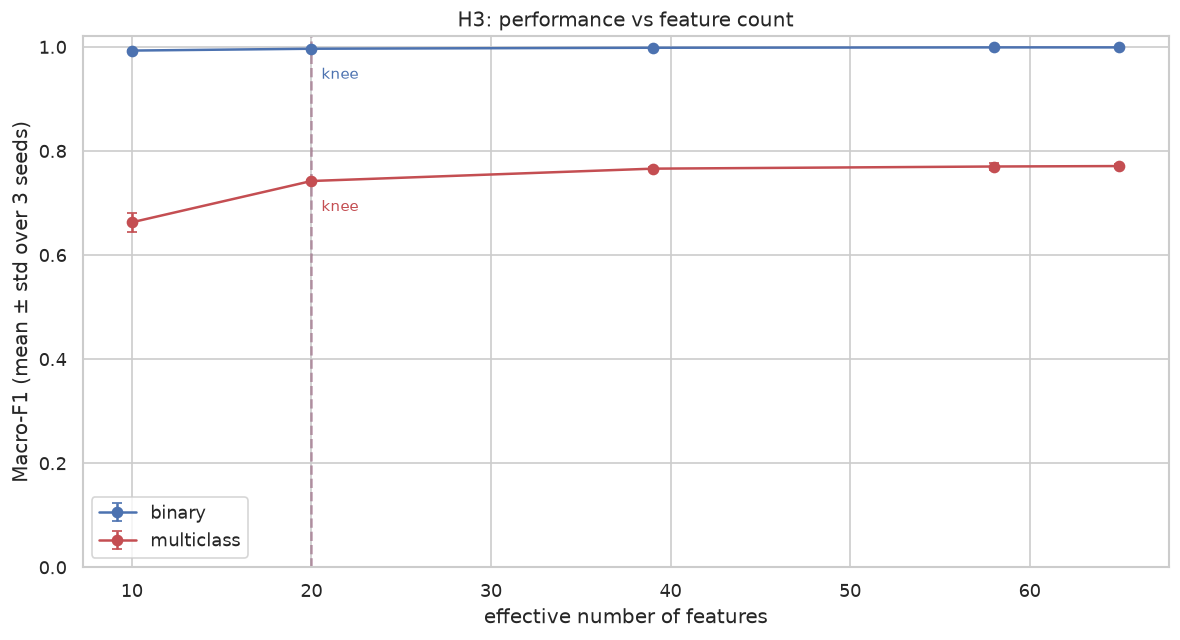

In [2]:
order = ["all", "75pct", "50pct", "25pct", "top10"]
agg = (
    results.groupby(["task", "variant", "n_features_effective"], observed=True)
    .agg(macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"), latency_med=("latency_ms_1000", "median"), latency_std=("latency_ms_1000", "std"))
    .reset_index()
)
agg["variant"] = pd.Categorical(agg["variant"], categories=order, ordered=True)
agg = agg.sort_values(["task", "variant"])
display(agg.round(4))

def knee_point(x, y):
    """Point of maximum perpendicular distance to the endpoint chord."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x = (x - x.min()) / max(x.max() - x.min(), 1e-12)
    y = (y - y.min()) / max(y.max() - y.min(), 1e-12)
    p0 = np.array([x[0], y[0]])
    p1 = np.array([x[-1], y[-1]])
    line = p1 - p0
    # 2-D cross product, written explicitly: np.cross no longer accepts
    # 2-D vectors in NumPy 2.x.
    distances = np.abs(
        line[0] * (y - p0[1]) - line[1] * (x - p0[0])
    ) / max(np.linalg.norm(line), 1e-12)
    return int(np.argmax(distances))

fig, ax = plt.subplots(figsize=(10, 5.5))
for task, color in [("binary", "#4c72b0"), ("multiclass", "#c44e52")]:
    part = agg[agg["task"] == task].sort_values("n_features_effective")
    ax.errorbar(part["n_features_effective"], part["macro_f1_mean"], yerr=part["macro_f1_std"], marker="o", capsize=3, label=task, color=color)
    k = knee_point(part["n_features_effective"], part["macro_f1_mean"])
    ax.axvline(part["n_features_effective"].iloc[k], color=color, linestyle="--", alpha=0.35)
    ax.annotate("knee", (part["n_features_effective"].iloc[k], part["macro_f1_mean"].iloc[k]), xytext=(6, -18), textcoords="offset points", color=color, fontsize=9)
ax.set_xlabel("effective number of features")
ax.set_ylabel("Macro-F1 (mean ± std over 3 seeds)")
ax.set_title("H3: performance vs feature count")
ax.set_ylim(0, 1.02)
ax.legend(title="")
fig.tight_layout()
fig.savefig(FIG / "05_exp3_performance.png", bbox_inches="tight")
plt.show()

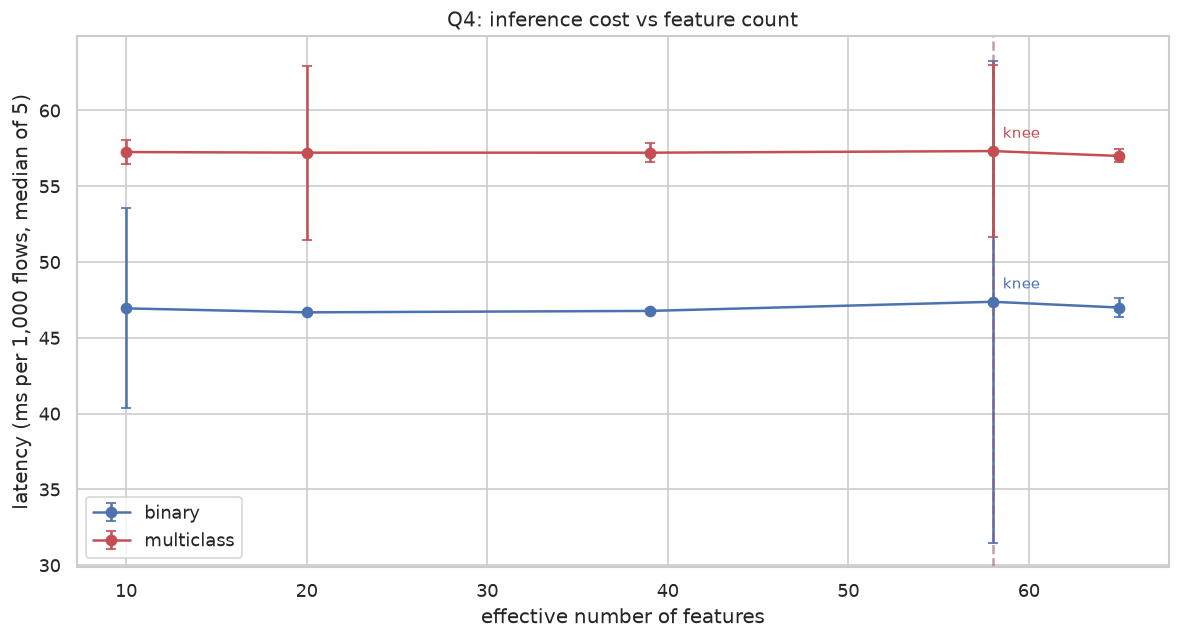

task,binary,multiclass
variant,,
all,46.99,57.00
75pct,47.37,57.32
50pct,46.77,57.21
25pct,46.68,57.21
top10,46.94,57.25


In [3]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for task, color in [("binary", "#4c72b0"), ("multiclass", "#c44e52")]:
    part = agg[agg["task"] == task].sort_values("n_features_effective")
    ax.errorbar(part["n_features_effective"], part["latency_med"], yerr=part["latency_std"], marker="o", capsize=3, label=task, color=color)
    k = knee_point(part["n_features_effective"], part["latency_med"])
    ax.axvline(part["n_features_effective"].iloc[k], color=color, linestyle="--", alpha=0.35)
    ax.annotate("knee", (part["n_features_effective"].iloc[k], part["latency_med"].iloc[k]), xytext=(6, 8), textcoords="offset points", color=color, fontsize=9)
ax.set_xlabel("effective number of features")
ax.set_ylabel("latency (ms per 1,000 flows, median of 5)")
ax.set_title("Q4: inference cost vs feature count")
ax.legend(title="")
fig.tight_layout()
fig.savefig(FIG / "05_exp3_latency.png", bbox_inches="tight")
plt.show()

display(agg.pivot(index="variant", columns="task", values="latency_med").round(2))

Spearman rho = 0.924 (p=4.25e-33)


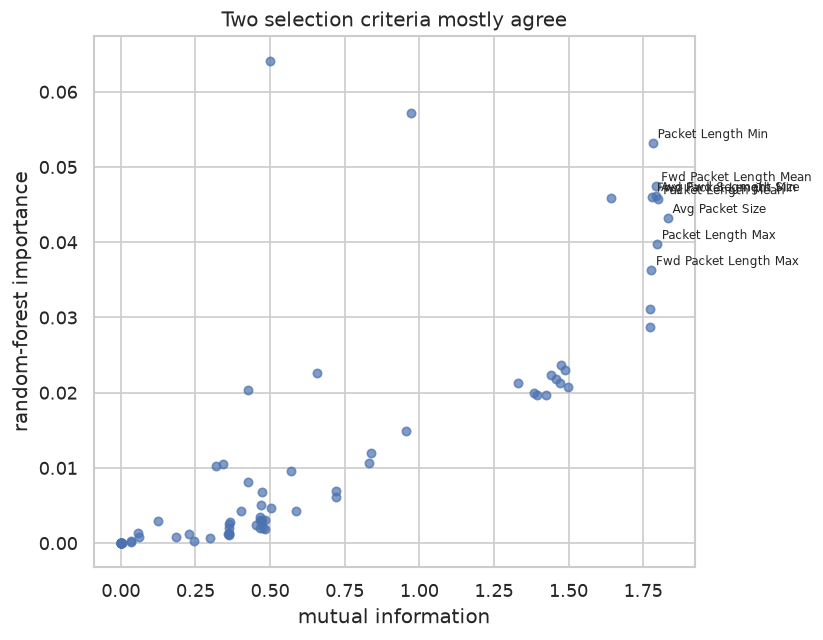

,feature,mutual_info,rf_importance,mi_rank,rf_rank
129,Avg Packet Size,1.8316,0.0432,1,9
117,Packet Length Mean,1.8004,0.0457,2,8
116,Packet Length Max,1.7958,0.0397,3,10
85,Fwd Packet Length Mean,1.7935,0.0474,4,4
130,Avg Fwd Segment Size,1.7929,0.0461,5,5
115,Packet Length Min,1.7818,0.0532,6,3
84,Fwd Packet Length Min,1.7791,0.0461,7,6
83,Fwd Packet Length Max,1.7761,0.0363,8,11
81,Fwd Packets Length Total,1.7727,0.0311,9,12
139,Subflow Fwd Bytes,1.7725,0.0287,10,13


In [4]:
# Cross-check: mutual information vs random-forest importance.
focus = ranking[(ranking["seed"] == ranking["seed"].min()) & (ranking["task"] == "multiclass")].copy()
rho, p = spearmanr(focus["mutual_info"], focus["rf_importance"])
print(f"Spearman rho = {rho:.3f} (p={p:.2e})")

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(focus["mutual_info"], focus["rf_importance"], s=25, alpha=0.7, color="#4c72b0")
for row in focus.nlargest(8, "mutual_info").itertuples():
    ax.annotate(row.feature, (row.mutual_info, row.rf_importance), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("mutual information")
ax.set_ylabel("random-forest importance")
ax.set_title("Two selection criteria mostly agree")
fig.tight_layout()
fig.savefig(FIG / "05_exp3_feature_agreement.png", bbox_inches="tight")
plt.show()

display(focus.nlargest(15, "mutual_info")[["feature", "mutual_info", "rf_importance", "mi_rank", "rf_rank"]].round(4))

## Verdict on H3, Q3 and Q4

**Observation.** The performance curve is not a straight line down: a subset
of features keeps most of the Macro-F1, and the Top-10 variant is where the
drop becomes visible.  The latency curve is flatter than the performance curve
for the random forest: removing features reduces fit time and memory more than
prediction time, because most of the cost is traversing 300 trees.

**Interprétation ML.** H3 is partially supported.  Mutual information and
random-forest importance rank the same packet-size and rate features at the top,
so the result is not an artefact of one selector.  The knee marks the point
where extra features stop buying much performance; below it, rare families lose
recall first.  Q3 answer: a few dozen features are enough for most of the
performance, but the exact number depends on whether the target is binary or
13-class.

**Interprétation cyber.** Q4 answer: for real-time use, the important numbers
are recall on the attack class, FPR on Benign and latency per batch, not
accuracy.  A Top-10 model is attractive for an edge sensor, but it must be
validated on the families that lose recall.  A random forest with 300 trees may
still be too slow for line-rate inspection; the feature-reduction curve tells
you where to stop, not that the model is deployable.

**Limite.** Latency is measured on one laptop, in batch, with a warm cache; it
is not a network-device benchmark.  Training was capped at 20,000 rows per
class, so the absolute scores are not directly comparable to Experiments 1--2.
The selector is univariate mutual information; multivariate selection could
find a smaller set with the same score.